[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/getting-started/python-basics/notebook.ipynb)

# Python Basics: hands-on

This notebook goes with the [topic README](README.md). You will run small pieces of Python, then NumPy, then draw a few plots. It needs only NumPy and Matplotlib and runs in a few seconds on a CPU.

Run the cells from top to bottom. After each demo, change a number and run it again: playing with the examples is the fastest way to learn. The [exercises](exercises/problems.md) are the next step, and the next topic is [Vectors and Matrices](../../math/linear-algebra/vectors-and-matrices/README.md).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=3, suppress=True)

## 1. Running code and reading errors

Click a code cell and press `Shift+Enter` to run it. `print` shows a value; a `#` starts a comment that Python ignores. If the last line of a cell is a bare value, the notebook shows it for you.

In [2]:
print("Hello, AI/ML!")

# Three apples at 4 coins each.
price = 4          # a comment can also sit after code
print(price * 3)

price * 5          # no print needed: the last value of a cell is displayed

Hello, AI/ML!
12


20

A mistyped name causes a `NameError`. Normally you would see a red traceback with the error on its last line. Here we catch the error with `try`/`except` so that the notebook keeps running, and print the message that the last line of the traceback would show.

In [3]:
total = 10
try:
    print(totl)           # typo: the name is "total"
except NameError as error:
    print("NameError:", error)

NameError: name 'totl' is not defined


## 2. Variables and basic types

A variable is a name attached to a value. The four basic types are `int`, `float`, `str`, and `bool`.

In [4]:
age = 25            # int
height = 1.75       # float
name = "Ada"        # str
is_student = True   # bool

for value in [age, height, name, is_student]:
    print(value, "has type", type(value))

25 has type <class 'int'>
1.75 has type <class 'float'>
Ada has type <class 'str'>
True has type <class 'bool'>


In [5]:
print(7 + 2, 7 - 2, 7 * 2)
print(7 / 2, 7 // 2, 7 % 2, 7 ** 2)

9 5 14
3.5 3 1 49


**f-strings** mix values into text, and `:.2f` fixes the number of decimals.

In [6]:
score = 0.91234
print(f"{name} scored {score:.2f}, which is {score * 100:.1f}%")

print(int("42") + 1, float("3.5") * 2, "score: " + str(7))

Ada scored 0.91, which is 91.2%
43 7.0 score: 7


Floats are approximate, so compare them by closeness rather than equality.

In [7]:
print(0.1 + 0.2)
print(0.1 + 0.2 == 0.3)
print(abs((0.1 + 0.2) - 0.3) < 1e-9)

0.30000000000000004
False
True


## 3. Lists, tuples, and dictionaries

Lists are ordered and counted from 0. A slice `a[start:stop]` includes `start` and excludes `stop`.

In [8]:
scores = [88, 92, 75, 64, 99]
print(scores[0], scores[-1])
print(scores[1:4])
print(scores[::2], scores[::-1])

scores.append(70)
print(len(scores), 92 in scores)

88 99
[92, 75, 64]
[88, 75, 99] [99, 64, 75, 92, 88]
6 True


Copying: `b = a` gives a second name for the same list.

In [9]:
a = [1, 2, 3]
b = a            # same list, two names
b.append(4)
print("a after changing b:", a)

c = a.copy()     # an independent copy
c.append(5)
print("a:", a, " c:", c)

a after changing b: [1, 2, 3, 4]
a: [1, 2, 3, 4]  c: [1, 2, 3, 4, 5]


In [10]:
shape = (3, 4)          # a tuple: cannot be changed
rows, cols = shape      # unpacking
print(rows, cols)

config = {"learning_rate": 0.01, "epochs": 20, "optimizer": "sgd"}
config["epochs"] = 50
config["batch_size"] = 32
for key, value in config.items():
    print(key, "->", value)
print(config.get("dropout", 0.0))

3 4
learning_rate -> 0.01
epochs -> 50
optimizer -> sgd
batch_size -> 32
0.0


## 4. Decisions and loops

`if`/`elif`/`else` choose a block to run. Indentation (four spaces) marks the block. Here a model's probability becomes a label.

In [11]:
def label_for(probability):
    if probability >= 0.9:
        return "definitely spam"
    elif probability >= 0.5:
        return "probably spam"
    else:
        return "not spam"

for p in [0.97, 0.73, 0.12]:
    print(p, "->", label_for(p))

0.97 -> definitely spam
0.73 -> probably spam
0.12 -> not spam


`for` repeats once per item, `range` counts, and `while` repeats until a condition fails. The `while` loop below mimics "keep going until the error is small enough".

In [12]:
words = ["cat", "dog", "bird"]
for i, word in enumerate(words):
    print(i, word, len(word))

print(list(range(2, 10, 3)))

loss = 8.0
steps = 0
while loss > 1.0:
    loss = loss / 2
    steps += 1
print("steps:", steps, "loss:", loss)

0 cat 3
1 dog 3
2 bird 4
[2, 5, 8]
steps: 3 loss: 1.0


In [13]:
squares = [n ** 2 for n in range(6)]
evens = [n for n in range(10) if n % 2 == 0]
fahrenheit = [c * 9 / 5 + 32 for c in [0, 20, 37]]
print(squares, evens, fahrenheit)

[0, 1, 4, 9, 16, 25] [0, 2, 4, 6, 8] [32.0, 68.0, 98.6]


## 5. Functions

`def` names a recipe, `return` hands back the result, and the docstring explains it. Default values make parameters optional.

In [14]:
def mean(values):
    """Return the average of a list of numbers."""
    return sum(values) / len(values)


def scale(values, factor=1.0, offset=0.0):
    """Return a new list with each value multiplied by factor, then shifted by offset."""
    return [v * factor + offset for v in values]


def min_and_max(values):
    """Return the smallest and largest value."""
    return min(values), max(values)


print(mean([88, 92, 75, 64, 99]))
print(scale([1, 2, 3], factor=2, offset=1))
low, high = min_and_max([4, 9, 2, 7])
print(low, high)
help(mean)

83.6
[3, 5, 7]
2 9
Help on function mean in module __main__:

mean(values)
    Return the average of a list of numbers.



A model is a function, and so is a loss. Small functions like these are the pieces that training loops are made of.

In [15]:
def predict(x, w, b):
    """A one-feature linear model: prediction = w * x + b."""
    return w * x + b


def squared_error(prediction, target):
    """How wrong a prediction is, as a non-negative number."""
    return (prediction - target) ** 2


print(squared_error(predict(3, 2.0, 1.0), 8))

1.0


## 6. Modules and imports

`import` loads code that is not available by default. We already imported `numpy as np` and `matplotlib.pyplot as plt` at the top.

In [16]:
import math
from math import exp

print(math.sqrt(16), math.pi, exp(0))
print(np.__name__, plt.__name__)

4.0 3.141592653589793 1.0
numpy matplotlib.pyplot


## 7. NumPy: fast arithmetic on arrays

### Arrays versus lists

Multiplying a list by 2 repeats it; multiplying an array by 2 doubles every entry.

In [17]:
a = [1, 2, 3]
x = np.array([1, 2, 3])

print(a * 2)
print(x * 2)
print(x + 10)
print(x + np.array([10, 20, 30]))

[1, 2, 3, 1, 2, 3]
[2 4 6]
[11 12 13]
[11 22 33]


### Creating arrays and reading their shape

Check the shape first, always. A flat `(3,)`, a column `(3, 1)`, and a row `(1, 3)` are three different things.

In [18]:
A = np.array([[1, 2, 3],
              [4, 5, 6]])
print(A.shape, A.ndim, A.size, A.dtype)

print(np.zeros((2, 3)))
print(np.ones(4))
print(np.arange(0, 10, 2))
print(np.linspace(0, 1, 5))
print(np.arange(12).reshape(3, 4))

v = np.array([1, 2, 3])
print(v.shape, v.reshape(3, 1).shape, v.reshape(1, 3).shape, v.reshape(-1, 1).shape)

(2, 3) 2 6 int64
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1. 1.]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(3,) (3, 1) (1, 3) (3, 1)


### Indexing, slicing, and masks

In [19]:
A = np.arange(12).reshape(3, 4)
print(A)
print("A[1, 2]   =", A[1, 2])
print("A[0]      =", A[0])
print("A[:, 1]   =", A[:, 1])
print("A[1:, :2] =\n", A[1:, :2])

scores = np.array([88, 92, 75, 64, 99])
print(scores > 80)
print(scores[scores > 80], scores[scores > 80].mean())

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
A[1, 2]   = 6
A[0]      = [0 1 2 3]
A[:, 1]   = [1 5 9]
A[1:, :2] =
 [[4 5]
 [8 9]]
[ True  True False False  True]
[88 92 99] 93.0


A slice is a *view* of the same data, not a copy. Changing the slice changes the original.

In [20]:
B = np.arange(6).reshape(2, 3)
row = B[0]
row[0] = 100
print(B)

safe = B[1].copy()
safe[0] = -1
print(B)

[[100   1   2]
 [  3   4   5]]
[[100   1   2]
 [  3   4   5]]


### Element-wise arithmetic and broadcasting

`*` multiplies entry by entry. Broadcasting lets a single number, or a row, be combined with a bigger array.

In [21]:
x = np.array([1.0, 2.0, 3.0])
y = np.array([10.0, 20.0, 30.0])
print(x + y, x * y, x ** 2, np.sqrt(x))

T = np.array([[1, 2, 3],
              [4, 5, 6]])
row = np.array([10, 20, 30])
print(T + 100)
print(T + row)

[11. 22. 33.] [10. 40. 90.] [1. 4. 9.] [1.    1.414 1.732]
[[101 102 103]
 [104 105 106]]
[[11 22 33]
 [14 25 36]]


### Vectorization: loops versus array expressions

We time the sum of squares of the numbers below $n$ two ways: a Python loop (in the form of a list comprehension) and one NumPy expression. Each timing uses the fastest of five runs. The exact numbers depend on your computer; the gap is what matters.

In [22]:
import time


def sum_of_squares_loop(values):
    return sum([v * v for v in values])      # a Python loop in disguise


def sum_of_squares_numpy(arr):
    return np.sum(arr * arr)                 # vectorized


def best_time(func, data, repeats=5):
    """Call func(data) several times and return the fastest time in seconds."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        func(data)
        times.append(time.perf_counter() - start)
    return min(times)


sizes = [1_000, 10_000, 100_000, 1_000_000]
loop_times, numpy_times = [], []
for n in sizes:
    loop_times.append(best_time(sum_of_squares_loop, list(range(n))))
    numpy_times.append(best_time(sum_of_squares_numpy, np.arange(n)))

for n, lt, nt in zip(sizes, loop_times, numpy_times):
    print(f"n = {n:>9,}: list {lt:.5f} s, numpy {nt:.6f} s, about {lt / nt:.0f}x faster")

n =     1,000: list 0.00002 s, numpy 0.000007 s, about 3x faster
n =    10,000: list 0.00017 s, numpy 0.000007 s, about 25x faster
n =   100,000: list 0.00210 s, numpy 0.000036 s, about 59x faster
n = 1,000,000: list 0.02676 s, numpy 0.000526 s, about 51x faster


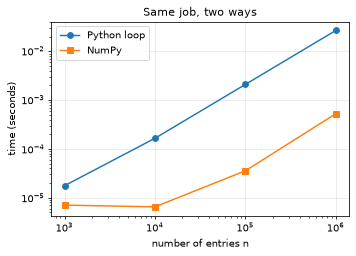

In [23]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(sizes, loop_times, "o-", label="Python loop")
ax.loglog(sizes, numpy_times, "s-", label="NumPy")
ax.set_xlabel("number of entries n")
ax.set_ylabel("time (seconds)")
ax.set_title("Same job, two ways")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Both lines rise with $n$, but the NumPy line sits far below the loop line. Deep learning leans on this idea heavily: GPUs apply it to millions of numbers at once.

### Dot product, `@`, and `axis`

In [24]:
w = np.array([0.5, -1.0, 2.0])
x = np.array([4.0, 2.0, 1.0])
print(np.dot(w, x), w @ x)

W = np.array([[1, 0, -1],
              [2, 1,  0]])    # shape (2, 3)
print(W @ x, (W @ x).shape)

# * versus @ on two same-shaped arrays gives different things
print(w * x)       # entry by entry
print(w @ x)       # sum of those entries

2.0 2.0
[ 3. 10.] (2,)
[ 2. -2.  2.]
2.0


In [25]:
data = np.array([[1, 2, 3],
                 [4, 5, 6]])     # 2 examples, 3 measurements

print(data.sum(), data.sum(axis=0), data.sum(axis=1))
print(data.mean(axis=0))

centred = data - data.mean(axis=0)
print(centred)
print(centred.mean(axis=0))

21 [5 7 9] [ 6 15]
[2.5 3.5 4.5]
[[-1.5 -1.5 -1.5]
 [ 1.5  1.5  1.5]]
[0. 0. 0.]


### Random numbers and seeds

The same seed gives the same "random" numbers every time, which makes an experiment reproducible.

In [26]:
rng = np.random.default_rng(seed=42)
print(rng.random(3))
print(rng.normal(loc=0, scale=1, size=(2, 3)))
print(rng.integers(0, 10, size=5))

a = np.random.default_rng(0).random(3)
b = np.random.default_rng(0).random(3)
c = np.random.default_rng(1).random(3)
print(np.array_equal(a, b), np.array_equal(a, c))

[0.774 0.439 0.859]
[[ 0.941 -1.951 -1.302]
 [ 0.128 -0.316 -0.017]]
[8 4 5 3 1]
True False


## 8. Matplotlib: seeing your data

A line plot joins points in order; a scatter plot shows one dot per example. `plt.subplots` gives you a grid of plot areas (axes) to draw on.

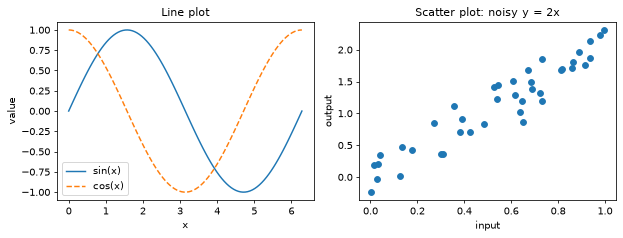

In [27]:
x = np.linspace(0, 2 * np.pi, 100)
rng = np.random.default_rng(0)
px = rng.random(40)
py = 2 * px + rng.normal(0, 0.2, size=40)    # a line y = 2x, plus noise

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))

ax1.plot(x, np.sin(x), label="sin(x)")
ax1.plot(x, np.cos(x), linestyle="--", label="cos(x)")
ax1.set_title("Line plot")
ax1.set_xlabel("x")
ax1.set_ylabel("value")
ax1.legend()

ax2.scatter(px, py)
ax2.set_title("Scatter plot: noisy y = 2x")
ax2.set_xlabel("input")
ax2.set_ylabel("output")

fig.tight_layout()
plt.show()

### Putting it together: a tiny model on arrays

The `predict` and `squared_error` functions from section 5 were written for single numbers, yet they work on whole arrays unchanged, because the arithmetic inside them is element-wise. We score two candidate lines on the noisy data from above, using the mean of the squared errors. The line with the smaller error fits better.

line A: mean squared error 0.051
line B: mean squared error 0.294


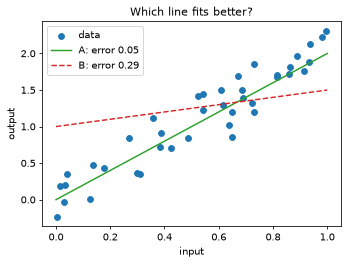

In [28]:
predictions_a = predict(px, w=2.0, b=0.0)     # close to how the data was made
predictions_b = predict(px, w=0.5, b=1.0)     # a poor guess

mse_a = squared_error(predictions_a, py).mean()
mse_b = squared_error(predictions_b, py).mean()
print(f"line A: mean squared error {mse_a:.3f}")
print(f"line B: mean squared error {mse_b:.3f}")

grid = np.linspace(0, 1, 50)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.scatter(px, py, label="data")
ax.plot(grid, predict(grid, 2.0, 0.0), color="C2", label=f"A: error {mse_a:.2f}")
ax.plot(grid, predict(grid, 0.5, 1.0), color="C3", linestyle="--", label=f"B: error {mse_b:.2f}")
ax.set_xlabel("input")
ax.set_ylabel("output")
ax.set_title("Which line fits better?")
ax.legend()
plt.show()

Finding the best line automatically, instead of guessing, is what [least squares](../../math/linear-algebra/projections-and-least-squares/README.md) and [gradient descent](../../math/calculus-and-optimization/gradient-descent-and-its-variants/README.md) do later in the roadmap.

## 9. Debugging habits

Print the shape before you multiply. Here a mismatched product is caught so the notebook continues; in your own work you would see the red traceback and read its last line.

In [29]:
A = np.ones((2, 3))
B = np.ones((2, 3))
print(A.shape, B.shape)

try:
    A @ B
except ValueError as error:
    print("ValueError:", str(error)[:60], "...")
    print("the end of the message:", str(error)[-30:])

print((A @ B.T).shape)     # transposing B makes the inner sizes match: (2, 3) @ (3, 2)

(2, 3) (2, 3)
ValueError: matmul: Input operand 1 has a mismatch in its core dimension ...
the end of the message: ) (size 2 is different from 3)
(2, 2)


In [30]:
x = np.zeros((4, 3))
assert x.shape == (4, 3), f"unexpected shape {x.shape}"
print("shape ok")

shape ok


## Your turn

1. Change the `0.1 + 0.2` comparison to use `0.5 + 0.25 == 0.75`. Why does that one print `True`? (Hint: some decimals are exactly representable in binary.)
2. Add a fourth `elif` branch to `label_for` for probabilities below `0.05` that returns `"very safe"`. Where must it go?
3. Make a `(4, 5)` array with `np.arange(20).reshape(4, 5)` and extract its last column, its second row, and every entry greater than 10.
4. Re-run the plotting cell with a different seed. What changes and what stays the same?

Then continue with the [exercises](exercises/problems.md) and the [assignment](assignment.md).